# TrOCR-Small cho OCR chữ laser trên PCB (PyTorch + Hugging Face)

- **Model:** `microsoft/trocr-small-printed` (~62M params). Có preset `base` (`microsoft/trocr-base-printed`).
- **Kiến trúc:** ViT encoder + Transformer decoder (`VisionEncoderDecoderModel`).
- **Ảnh:** resize / letterbox về **384×384** (chuẩn TrOCR), RGB.
- **Nhãn nhiều dòng:** SentencePiece coi `\n` như space → encode tạm bằng ` | `, decode ngược lại khi suy luận.

Notebook **tuân thủ protocol chung** (`PCB_OCR_Training_Protocol_v1.0.md`) giống các baseline khác (PARSeq, …) để so sánh công bằng:

| Hạng mục | Cách thực hiện |
|---|---|
| Dataset | Giữ đủ 2.120 / 455 dòng. Không loại nhãn rỗng hay ký tự lạ (chỉ báo cáo). Thiếu ảnh → lỗi |
| Split | **90/10 theo capture gốc**, `CFG.split_seed=42`. Xuất `split_manifest.csv` + SHA256 |
| Chống leakage | `_aug` đi theo capture gốc. Val **chỉ mẫu gốc** |
| Test | Giữ nguyên `test.csv`. Chỉ chạy khi `CFG.final_test = True` |
| Nhãn | Không `upper()`, không `strip()`. Chỉ NFC + line ending (`norm_label`) |
| Metric | **CER corpus-level** (chính); SeqAcc, 1-NED, LineAcc, EmptyPred_rate |
| Checkpoint | Best **val CER**; hòa → val loss thấp hơn |
| Seed | Screening `[42]`; xác nhận `[42, 43, 44]` |


## 0. Tuân thủ cấu hình chung bắt buộc

| Hạng mục | Cách notebook thực hiện | Nơi thực hiện |
|---|---|---|
| Dataset | Giữ đủ 2.120 / 455 dòng. Không loại nhãn | §2 |
| Split | 90/10 theo capture gốc, `split_seed` cố định, manifest + hash | §2 |
| Chống leakage | `_aug` theo capture; val chỉ gốc | §2 |
| Test | Chỉ khi `CFG.final_test = True` | §9 |
| Nhãn | `norm_label`: NFC + line ending, **không** upper/strip | §2 |
| Metric | CER corpus-level; SeqAcc, 1-NED, … | §4 |
| Checkpoint | Best val CER | §5 |
| Seed | `CFG.seeds = [42]` screening | §7 |
| Precision | `auto` → FP16 trên T4 / BF16 nếu hỗ trợ | §1, §5 |
| Board-disjoint | `CFG.split_mode = "board"` → thư mục riêng | §1 |

**Khác PARSeq (chỉ phần model):** không có PLM / permutation, không charset tự dựng, không refine cloze. Loss = cross-entropy của decoder HF; suy luận = `model.generate` (greedy hoặc beam).


In [2]:
import os, math, random, time, copy, string
import hashlib, json, re, sys, subprocess, platform, contextlib, unicodedata, datetime
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

# transformers / TrOCR
def pip_install(pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])

try:
    import sentencepiece  # noqa: F401
except Exception:
    pip_install(["sentencepiece", "protobuf"])

try:
    import tokenizers  # noqa: F401
except Exception:
    pip_install(["tokenizers"])

try:
    import transformers
    print("transformers", transformers.__version__)
except Exception:
    pip_install(["transformers>=4.40,<4.50", "accelerate"])
    import transformers

from transformers import (
    TrOCRProcessor,
    VisionEncoderDecoderModel,
    get_cosine_schedule_with_warmup,
)

try:
    import cv2
except ImportError:
    cv2 = None

print("torch", torch.__version__)
print("cuda:", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")


transformers 5.22.0
torch 2.11.0+cpu
cuda: False 


## 1. Cấu hình

- `preset`: `"small"` (~62M, batch 16) hoặc `"base"` (nặng hơn, batch 4–6 trên T4).
- `model_name`: Hugging Face id (`microsoft/trocr-small-printed` / `trocr-base-printed`).
- `img_size`: **384** (chuẩn TrOCR; không dùng 192 như PARSeq).
- `max_target_length`: 64 — hằng số chung nhóm; không cắt nhãn âm thầm.
- `split_mode`: `"capture"` (**official**, 90/10) hoặc `"board"` (chỉ phân tích generalization).
- `split_seed`: seed của split, **cố định**, tách khỏi seed huấn luyện.
- `seeds`: screening `[42]`; xác nhận `[42, 43, 44]`.
- `precision`: `"auto"` → FP16 trên T4 / BF16 nếu GPU hỗ trợ.
- `num_beams`: beam lúc `generate` (evaluate / test); train chỉ teacher-forcing.
- `final_test`: `False` đến khi đã khóa phương pháp trên val.


In [3]:
def locate(name, is_dir=False, roots=(".", "data", "/kaggle/input", "/content", "/content/drive")):
    for r in roots:
        if not os.path.exists(r):
            continue
        for dp, dns, fns in os.walk(r):
            if (name in dns) if is_dir else (name in fns):
                return Path(dp) / name
    return None


class CFG:
    # --- đường dẫn đã được sửa để phù hợp với thư mục tải trên Google Colab ---
    train_csv = Path("/content/datasets/binbinkin/pcb-dataset/train.csv")
    test_csv  = Path("/content/datasets/binbinkin/pcb-dataset/test.csv")
    img_root  = Path("/content/datasets/binbinkin/pcb-dataset/multi_view_v2")
    out_dir   = Path("outputs_trocr_small")

    all_views   = ["DF_path", "PO_path", "CO_path"]
    train_views = ["DF_path", "PO_path", "CO_path"]
    label_col   = "title"

    # --- dữ liệu chính thức ---
    expected_train_rows = 2120
    expected_train_orig = 1060
    expected_test_rows  = 455

    # --- nhãn: giữ nguyên hoa/thường; chỉ chuẩn hóa encoding / line ending ---
    literal_backslash_n_to_newline = True
    max_target_length = 64          # hằng số chung nhóm

    # --- mô hình (ghi đè bởi preset) ---
    preset      = "small"
    model_name  = "microsoft/trocr-small-printed"
    img_size    = 384
    preprocess  = "autocontrast"    # "autocontrast" | "clahe" | "none"

    # --- train ---
    batch_size    = 16
    epochs        = 100
    min_epochs    = 25
    patience      = 20
    lr            = 5e-5
    warmup_ratio  = 0.03
    weight_decay  = 0.01
    grad_clip     = 1.0
    num_beams     = 4
    augment       = True
    precision     = "auto"          # "auto" | "fp16" | "bf16" | "fp32"
    trsub_n       = 96

    # --- split ---
    split_mode  = "capture"         # "capture" = OFFICIAL | "board" = generalization only
    val_ratio   = 0.10
    board_val_ratio = 0.15
    split_seed  = 42
    split_manifest_in  = None
    expected_split_hash = None

    # --- seed huấn luyện ---
    seeds = [42]
    seed  = 42
    num_workers = 2

    # --- khác ---
    final_test = False
    git_commit = None


PRESETS = {
    "small": dict(
        model_name="microsoft/trocr-small-printed",
        batch_size=16,
        lr=5e-5,
    ),
    "base": dict(
        model_name="microsoft/trocr-base-printed",
        batch_size=6,
        lr=3e-5,
    ),
}


def apply_preset(name):
    for k, v in PRESETS[name].items():
        setattr(CFG, k, v)
    CFG.preset = name


if not CFG.train_csv.exists():
    CFG.train_csv = locate("train.csv") or CFG.train_csv
if not CFG.test_csv.exists():
    CFG.test_csv = locate("test.csv") or CFG.test_csv
if not CFG.img_root.exists():
    CFG.img_root = locate("multi_view_v2", is_dir=True) or CFG.img_root

print("train_csv:", CFG.train_csv)
print("test_csv :", CFG.test_csv)
print("img_root :", CFG.img_root)

if CFG.split_mode == "board":
    CFG.out_dir = Path("outputs_trocr_board_analysis")
    print("!!! split_mode = 'board': chỉ phân tích generalization →", CFG.out_dir)

apply_preset(CFG.preset)
CFG.out_dir.mkdir(parents=True, exist_ok=True)
VIEW_NAME = {"DF_path": "DF", "PO_path": "PO", "CO_path": "CO"}


def set_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def resolve_precision(p):
    if p != "auto":
        return p
    if not torch.cuda.is_available():
        return "fp32"
    major, _ = torch.cuda.get_device_capability()
    if major >= 8 and torch.cuda.is_bf16_supported():
        return "bf16"
    return "fp16"


set_seed(CFG.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CFG.precision_resolved = resolve_precision(CFG.precision)
AMP_DTYPE = {"fp16": torch.float16, "bf16": torch.bfloat16}.get(CFG.precision_resolved)
print("device:", device, "| precision:", CFG.precision_resolved,
      "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)
print("preset:", CFG.preset, "|", CFG.model_name)

train_csv: /content/datasets/binbinkin/pcb-dataset/train.csv
test_csv : /content/datasets/binbinkin/pcb-dataset/test.csv
img_root : /content/datasets/binbinkin/pcb-dataset/multi_view_v2
device: cpu | precision: fp32 | GPU: None
preset: small | microsoft/trocr-small-printed


## 2. Đọc dữ liệu, chuẩn hóa nhãn, chia train/val

**Không loại mẫu nào.** Nhãn rỗng / ký tự lạ chỉ **báo cáo**.

**`norm_label` (chung nhóm):**
1. `dtype=str`, `keep_default_na=False`
2. Unicode NFC
3. `\r\n` / `\r` → `\n`
4. (cờ) chuỗi 2 ký tự `\n` → xuống dòng thật
5. **Không** strip, **không** upper, **không** xóa ký tự

**Split:** `capture_id` từ tên file DF (bỏ `_aug` và token view). 10% capture gốc → val (`split_seed`). `_aug` theo capture; val chỉ đánh giá mẫu gốc.


In [4]:
def sha256_bytes(b):
    return hashlib.sha256(b).hexdigest()

def sha256_file(p):
    return sha256_bytes(Path(p).read_bytes())

def read_csv_raw(path):
    return pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")

train_raw = read_csv_raw(CFG.train_csv)
test_raw  = read_csv_raw(CFG.test_csv)
print("train.csv:", train_raw.shape, "| test.csv:", test_raw.shape)
if len(train_raw) != CFG.expected_train_rows or len(test_raw) != CFG.expected_test_rows:
    raise ValueError(
        f"Số dòng không khớp bộ chính thức: train {len(train_raw)} (cần {CFG.expected_train_rows}), "
        f"test {len(test_raw)} (cần {CFG.expected_test_rows})"
    )

DATA_HASHES = {"train.csv": sha256_file(CFG.train_csv), "test.csv": sha256_file(CFG.test_csv)}
print("sha256 train.csv:", DATA_HASHES["train.csv"][:16], "| test.csv:", DATA_HASHES["test.csv"][:16])


def norm_label(s):
    """Chỉ chuẩn hóa encoding + line ending. KHÔNG strip, KHÔNG đổi hoa/thường, KHÔNG xóa ký tự."""
    s = "" if s is None or (isinstance(s, float) and np.isnan(s)) else str(s)
    s = unicodedata.normalize("NFC", s)
    s = s.replace("\r\n", "\n").replace("\r", "\n")
    if CFG.literal_backslash_n_to_newline:
        s = s.replace("\\r\\n", "\n").replace("\\n", "\n")
    return s


IMG_INDEX = {}
for dp, _, fns in os.walk(CFG.img_root):
    for fn in fns:
        IMG_INDEX.setdefault(fn, os.path.join(dp, fn))
print(f"Tìm thấy {len(IMG_INDEX)} file trong {CFG.img_root}")


def resolve_path(p):
    p = str(p).replace("\\", "/")
    for base in (CFG.img_root, Path("."), Path("data")):
        cand = Path(base) / p
        if cand.exists():
            return str(cand)
    return IMG_INDEX.get(os.path.basename(p))


LEGACY_CHARS = set("ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789 \n+-.")  # chỉ thống kê


def prepare(df, name):
    df = df.copy().reset_index(drop=True)
    df.insert(0, "row_id", np.arange(len(df)))
    df["title_raw"] = df[CFG.label_col]
    df[CFG.label_col] = df["title_raw"].map(norm_label)
    for v in CFG.all_views:
        df[v + "_abs"] = df[v].map(resolve_path)
    missing = df[[v + "_abs" for v in CFG.all_views]].isna().any(axis=1)
    if missing.any():
        raise FileNotFoundError(
            f"[{name}] {missing.sum()} dòng thiếu ảnh, ví dụ: "
            f"{df.loc[missing, CFG.all_views].head(3).values.tolist()}"
        )
    L = df[CFG.label_col]
    odd = L.map(lambda s: not set(s) <= LEGACY_CHARS)
    print(
        f"[{name}] {len(df)} dòng (GIỮ NGUYÊN) | nhãn rỗng: {(L == '').sum()} | "
        f"có chữ thường: {L.str.contains('[a-z]', regex=True).sum()} | "
        f"ký tự ngoài A-Z0-9 +-.: {odd.sum()}"
    )
    if odd.sum():
        print("   ví dụ (đã chuẩn hóa):", [repr(x) for x in L[odd].head(6)])
    return df


train_all = prepare(train_raw, "train")
test_df   = prepare(test_raw,  "test")

# ---- capture_id / is_aug / board ----
AUG_RE  = re.compile(r"(^|_)aug\d*(?=_|$)", re.I)
VIEW_RE = re.compile(r"(^|_)(DF|PO|CO)(?=_|$)")


def _stem(p):
    return os.path.splitext(os.path.basename(str(p).replace("\\", "/")))[0]


def parse_capture(df):
    stems = df[CFG.all_views[0]].map(_stem)
    df["is_aug"] = np.logical_or.reduce([
        df[v].map(lambda p: bool(AUG_RE.search(_stem(p)))).values for v in CFG.all_views
    ])
    df["capture_id"] = stems.map(lambda s: VIEW_RE.sub("", AUG_RE.sub("", s)).strip("_"))
    df["board"] = df["capture_id"].map(lambda s: s.split("_")[0])
    return df


train_all = parse_capture(train_all)
test_df   = parse_capture(test_df)

n_orig = int((~train_all.is_aug).sum())
n_aug  = int(train_all.is_aug.sum())
print(
    f"[train] gốc: {n_orig} | _aug: {n_aug} | capture gốc: "
    f"{train_all.loc[~train_all.is_aug, 'capture_id'].nunique()} | board: {train_all.board.nunique()}"
)
if n_orig != CFG.expected_train_orig or n_aug != CFG.expected_train_rows - CFG.expected_train_orig:
    print(
        f"[CẢNH BÁO] kỳ vọng {CFG.expected_train_orig} gốc + "
        f"{CFG.expected_train_rows - CFG.expected_train_orig} _aug."
    )


train.csv: (2120, 4) | test.csv: (455, 4)
sha256 train.csv: 017963db097cc067 | test.csv: 20dc321533062396
Tìm thấy 7782 file trong /content/datasets/binbinkin/pcb-dataset/multi_view_v2
[train] 2120 dòng (GIỮ NGUYÊN) | nhãn rỗng: 20 | có chữ thường: 2 | ký tự ngoài A-Z0-9 +-.: 4
   ví dụ (đã chuẩn hóa): ["'JA-80\\\\'", "'EM638325TS-5G\\nl403705A0T205 11M\\nETRONTECH'", "'JA-80\\\\'", "'EM638325TS-5G\\nl403705A0T205 11M\\nETRONTECH'"]
[test] 455 dòng (GIỮ NGUYÊN) | nhãn rỗng: 4 | có chữ thường: 3 | ký tự ngoài A-Z0-9 +-.: 3
   ví dụ (đã chuẩn hóa): ["'E8002D\\\\Ncjc1w1'", "'EM638325TS-5G\\nl403705a0t205 11M\\nETRONTECH'", "'EM638325TS-5G\\nl403705A0T205 11M\\nETRONTECH'"]
[train] gốc: 1060 | _aug: 1060 | capture gốc: 1060 | board: 34


In [5]:
# ---------------------------------------------------------------- SPLIT (một lần, cố định, manifest + hash)
def manifest_hash(m):
    s = m[["row_id", "capture_id", "is_aug", "split"]].sort_values("row_id").to_csv(
        index=False, lineterminator="\n"
    )
    return sha256_bytes(s.encode("utf-8"))


def make_split(df):
    rng = np.random.RandomState(CFG.split_seed)
    if CFG.split_mode == "capture":
        key, ratio = "capture_id", CFG.val_ratio
        units = sorted(df.loc[~df.is_aug, key].unique())
    elif CFG.split_mode == "board":
        key, ratio = "board", CFG.board_val_ratio
        units = sorted(df[key].unique())
    else:
        raise ValueError("split_mode phải là 'capture' hoặc 'board'")
    units = np.array(units)
    rng.shuffle(units)
    n_val = max(1, int(round(len(units) * ratio)))
    val_units = set(units[:n_val].tolist())
    return np.where(df[key].isin(val_units), "val", "train")


if CFG.split_manifest_in and Path(CFG.split_manifest_in).exists():
    shared = pd.read_csv(CFG.split_manifest_in, dtype={"split": str})
    if set(shared.row_id) != set(train_all.row_id):
        raise ValueError("split_manifest_in không khớp train.csv (khác tập row_id)")
    train_all["split"] = train_all.row_id.map(shared.set_index("row_id")["split"])
    print("[split] nạp manifest dùng chung:", CFG.split_manifest_in)
else:
    train_all["split"] = make_split(train_all)
    print(f"[split] tạo mới | mode={CFG.split_mode} | split_seed={CFG.split_seed}")

if not set(train_all.split) <= {"train", "val"}:
    raise ValueError("cột split chỉ được nhận 'train' hoặc 'val'")

manifest = train_all[["row_id", "capture_id", "board", "is_aug", "split"] + CFG.all_views].copy()
SPLIT_HASH = manifest_hash(manifest)
sfx = "" if CFG.split_mode == "capture" else "_board"
manifest.to_csv(CFG.out_dir / f"split_manifest{sfx}.csv", index=False)
(CFG.out_dir / f"split_hash{sfx}.txt").write_text(SPLIT_HASH + "\n")
if CFG.expected_split_hash and CFG.expected_split_hash != SPLIT_HASH:
    raise ValueError(
        f"Split hash khác của nhóm!\n  nhóm : {CFG.expected_split_hash}\n  của bạn: {SPLIT_HASH}"
    )

tr_rows  = train_all[train_all.split == "train"]
val_rows = train_all[train_all.split == "val"]

assert not (set(tr_rows.capture_id) & set(val_rows.capture_id)), "LEAK: capture ở cả train và val"
assert not (set(tr_rows.row_id) & set(val_rows.row_id))
if CFG.split_mode == "board":
    assert not (set(tr_rows.board) & set(val_rows.board)), "LEAK: board ở cả train và val"
assert len(tr_rows) + len(val_rows) == len(train_all)

train_df = tr_rows.reset_index(drop=True)
val_df   = val_rows[~val_rows.is_aug].reset_index(drop=True)
val_aug_unused = int(val_rows.is_aug.sum())

overlap = set(test_df.capture_id) & set(train_all.capture_id)
if overlap:
    print(f"[CẢNH BÁO] {len(overlap)} capture_id test trùng train, ví dụ: {sorted(overlap)[:3]}")

print(
    f"train: {len(train_df)} dòng ({int((~train_df.is_aug).sum())} gốc + {int(train_df.is_aug.sum())} _aug) | "
    f"val: {len(val_df)} mẫu gốc (+{val_aug_unused} _aug không dùng) | test: {len(test_df)}"
)
n_tr_orig = int((~train_df.is_aug).sum())
print(
    f"tỉ lệ capture gốc train/val: {n_tr_orig}/{len(val_df)} = "
    f"{n_tr_orig / (len(val_df) + n_tr_orig):.3f}/{len(val_df) / (len(val_df) + n_tr_orig):.3f}"
)
print("SPLIT HASH:", SPLIT_HASH)
print("-> để khóa split, đặt CFG.expected_split_hash = '%s...' (đủ 64 ký tự)" % SPLIT_HASH[:16])

# max length check
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    mx = int(d[CFG.label_col].str.len().max()) if len(d) else 0
    print(f"độ dài nhãn tối đa [{name}] = {mx} (CFG.max_target_length = {CFG.max_target_length})")
    if mx > CFG.max_target_length:
        raise ValueError(
            f"Nhãn {name} dài {mx} > CFG.max_target_length={CFG.max_target_length}. "
            "Nâng hằng số (dùng chung cả nhóm) rồi chạy lại."
        )

lens = train_df[CFG.label_col].str.len()
print("độ dài nhãn (train): min/mean/max =", int(lens.min()), round(lens.mean(), 2), int(lens.max()))
print(
    "số dòng trung bình:", round(train_df[CFG.label_col].str.count("\n").add(1).mean(), 2),
    "| tỉ lệ nhãn nhiều dòng:", round(train_df[CFG.label_col].str.contains("\n", regex=False).mean(), 3),
)


[split] tạo mới | mode=capture | split_seed=42
train: 1908 dòng (954 gốc + 954 _aug) | val: 106 mẫu gốc (+106 _aug không dùng) | test: 455
tỉ lệ capture gốc train/val: 954/106 = 0.900/0.100
SPLIT HASH: 495f92f5e14f1048a6a5308649164dad040793e92e3ff6b2e26c13400aac6959
-> để khóa split, đặt CFG.expected_split_hash = '495f92f5e14f1048...' (đủ 64 ký tự)
độ dài nhãn tối đa [train] = 45 (CFG.max_target_length = 64)
độ dài nhãn tối đa [val] = 44 (CFG.max_target_length = 64)
độ dài nhãn tối đa [test] = 47 (CFG.max_target_length = 64)
độ dài nhãn (train): min/mean/max = 0 9.22 45
số dòng trung bình: 1.73 | tỉ lệ nhãn nhiều dòng: 0.466


## 3. Dataset, tiền xử lý ảnh và DataLoader

1. Enhance (`autocontrast` / CLAHE / none)
2. Augmentation nhẹ (chỉ train): RandomAffine **degrees=4**, translate 0.02, scale 0.95–1.05 + ColorJitter
3. Letterbox vuông `CFG.img_size` (384)
4. `TrOCRProcessor` → `pixel_values`; nhãn qua `encode_label` → token ids (pad = -100)

> `encode_label` / `processor` / `build_model` định nghĩa ở **§4 Mô hình TrOCR** (thay block Tokenizer + PARSeq).


In [6]:
# ---------------------------------------------------------------- Dataset / augment / DataLoader (ảnh → pixel_values TrOCR)
# encode_label / decode_label / processor / build_model nằm ở §4 (model).

_IMG_CACHE = {}


def enhance(img):
    if CFG.preprocess == "none":
        return img
    if CFG.preprocess == "autocontrast":
        return ImageOps.autocontrast(img, cutoff=1)
    if CFG.preprocess == "clahe" and cv2 is not None:
        arr = np.array(img.convert("L"))
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        arr = clahe.apply(arr)
        return Image.fromarray(arr).convert("RGB")
    return ImageOps.autocontrast(img, cutoff=1)


def letterbox(img, size):
    w, h = img.size
    scale = size / max(w, h)
    nw, nh = max(1, int(round(w * scale))), max(1, int(round(h * scale)))
    img = img.resize((nw, nh), Image.BICUBIC)
    fill = tuple(int(x) for x in np.array(img).reshape(-1, 3).mean(0))   # ← THÊM dòng này
    canvas = Image.new("RGB", (size, size), fill)                        # ← ĐỔI từ (0,0,0)
    canvas.paste(img, ((size - nw) // 2, (size - nh) // 2))
    return canvas


def load_image(path):
    path = str(path)
    if path not in _IMG_CACHE:
        _IMG_CACHE[path] = Image.open(path).convert("RGB")
    return _IMG_CACHE[path].copy()


class PCBDataset(Dataset):
    def __init__(self, df, view_col, train=False):
        self.df = df.reset_index(drop=True)
        self.view_col = view_col
        self.train = train
        self.aug = T.Compose([
            T.RandomChoice([
                T.Lambda(lambda img: img),                          # 0°
                T.Lambda(lambda img: img.transpose(Image.ROTATE_90)),   # 90°
                T.Lambda(lambda img: img.transpose(Image.ROTATE_180)),  # 180°
                T.Lambda(lambda img: img.transpose(Image.ROTATE_270)),  # 270°
            ]),
            T.RandomAffine(
                degrees=4,                    # vẫn giữ ±4° nhỏ
                translate=(0.02, 0.02),
                scale=(0.95, 1.05),
                fill=128,
            ),
            T.ColorJitter(brightness=0.15, contrast=0.15),
        ]) if (train and CFG.augment) else None

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        col_abs = self.view_col + "_abs"
        path = row[col_abs] if col_abs in row.index else resolve_path(row[self.view_col])
        img = load_image(path)
        img = enhance(img)
        if self.aug is not None:
            img = self.aug(img)
        img = letterbox(img, CFG.img_size)
        return {"image": img, "text": row[CFG.label_col], "path": path}


def collate_fn(batch):
    images = [b["image"] for b in batch]
    texts  = [encode_label(b["text"]) for b in batch]
    pixel_values = processor(images=images, return_tensors="pt").pixel_values
    labels = processor.tokenizer(
        texts,
        padding="max_length",
        max_length=CFG.max_target_length,
        truncation=True,
        return_tensors="pt",
    ).input_ids
    labels[labels == processor.tokenizer.pad_token_id] = -100
    return {
        "pixel_values": pixel_values,
        "labels": labels,
        "texts": [b["text"] for b in batch],
        "paths": [b["path"] for b in batch],
    }


def make_loader(df, view_col, train=False, batch_size=None):
    ds = PCBDataset(df, view_col, train=train)
    return DataLoader(
        ds,
        batch_size=batch_size or CFG.batch_size,
        shuffle=train,
        num_workers=CFG.num_workers,
        collate_fn=collate_fn,
        pin_memory=torch.cuda.is_available(),
        drop_last=False,
    )


print("Dataset helpers sẵn sàng (gọi make_loader sau khi đã load processor ở §4)")


Dataset helpers sẵn sàng (gọi make_loader sau khi đã load processor ở §4)


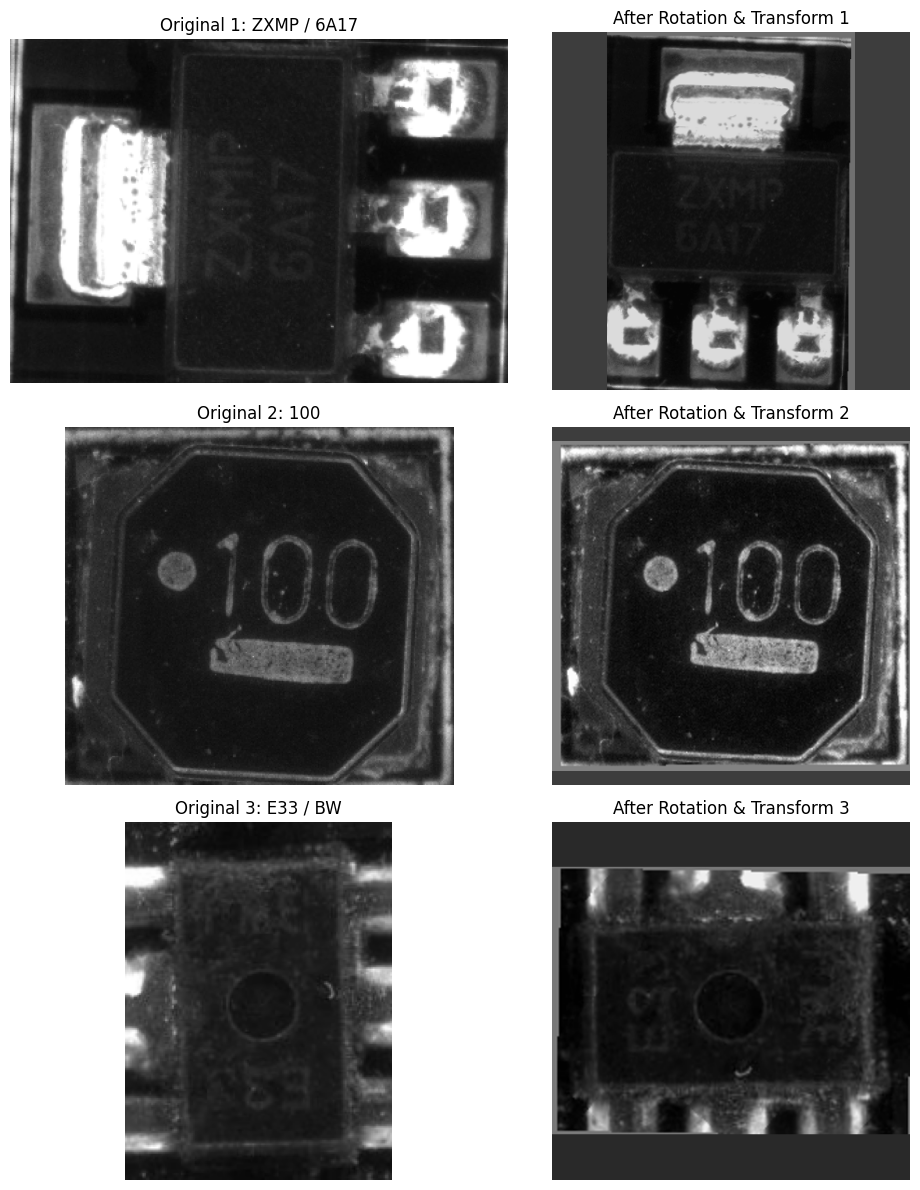

In [13]:
def show_rotation_augmentation(n=3):
    """Randomly visualize the original images and their rotated variations from the Dataset."""
    import matplotlib.pyplot as plt
    import numpy as np
    from PIL import Image

    # Set up training dataset with augmentations enabled
    ds_train_demo = PCBDataset(train_df, CFG.train_views[0], train=True)
    idx = np.random.RandomState(42).choice(len(train_df), size=min(n, len(train_df)), replace=False)

    fig, axes = plt.subplots(n, 2, figsize=(10, 4 * n))
    if n == 1:
        axes = axes[None, :]

    for r, i in enumerate(idx):
        row = train_df.iloc[i]
        path = row[CFG.train_views[0] + "_abs"]
        raw_img = Image.open(path).convert("RGB")

        # Retrieve augmented sample directly from the Dataset
        augmented_sample = ds_train_demo[i]
        proc_img = augmented_sample["image"]

        axes[r, 0].imshow(raw_img)
        axes[r, 0].set_title(f"Original {r+1}: {row[CFG.label_col].replace('\n', ' / ')}")
        axes[r, 0].axis("off")

        axes[r, 1].imshow(proc_img)
        axes[r, 1].set_title(f"After Rotation & Transform {r+1}")
        axes[r, 1].axis("off")

    plt.tight_layout()
    plt.show()

# Run the visualization on 3 sample images
show_rotation_augmentation(3)

## 4. Mô hình TrOCR

```
ảnh RGB 384×384
  → ViT encoder (pretrained) → encoder hidden states
  → Transformer decoder (cross-attn) → LM head → token ids
  → tokenizer.decode → chuỗi ký tự
```

**Khác PARSeq:** không tự cài `Tokenizer` / ViT / Decoder / PLM. Dùng `VisionEncoderDecoderModel` + `TrOCRProcessor` từ Hugging Face.

| | PARSeq (notebook mẫu) | TrOCR-Small (file này) |
|---|---|---|
| Tokenizer | class `Tokenizer` charset `[E][B][P]` | SentencePiece (XLM-R) trong HF |
| Encoder | ViT tự viết, patch 12/8 | ViT trong `microsoft/trocr-*-printed` |
| Decoder | two-stream + PLM + refine | Transformer decoder HF, teacher-forcing |
| Loss | `model.loss` (PLM) | `outputs.loss` (CE, pad=-100) |
| Suy luận | AR + refine cloze | `model.generate` (+ beam tùy chọn) |
| Ảnh | 192×192, 1 kênh | **384×384**, RGB |

Multi-line: SentencePiece biến `\n` thành space → encode `\n` thành ` | `, decode ngược khi suy luận.


In [22]:
# ---------------------------------------------------------------- TrOCR: processor (tokenizer + image) + model
# Thay cho block Tokenizer / Encoder / Decoder / PARSeq của notebook PARSeq.

import re
from transformers import (
    ViTImageProcessor,
    AutoImageProcessor,
    TrOCRProcessor,
    VisionEncoderDecoderModel,
)

# SentencePiece chuẩn hoá "\n" → space. Dùng "|" giữ ranh giới dòng (không nằm trong charset nhãn PCB).
def encode_label(s):
    return s.replace("\n", " | ")


def decode_label(t):
    """Giữ hoa/thường theo protocol (không upper/strip)."""
    return re.sub(r"\s*\|\s*", "\n", t)


def check_tokenizer(tok):
    probe = "E88441\n94V-0\nX2714"
    ids = tok(encode_label(probe)).input_ids
    dec = tok.decode(ids, skip_special_tokens=True)
    a = re.sub(r"\s+", "", encode_label(probe))
    b = re.sub(r"\s+", "", dec)
    if a != b:
        raise ValueError(f"roundtrip sai: {probe!r} -> {dec!r}")


def load_processor(model_name):
    """Load TrOCR processor ổn định (transformers 5.x / Kaggle).

    trocr-small-printed dùng SentencePiece (XLM-R), KHÔNG phải Roberta/GPT-2 BPE.
    Load nhầm tokenizer → decode ra chuỗi rỗng.
    """
    try:
        import sentencepiece  # noqa: F401
    except Exception:
        pip_install(["sentencepiece", "protobuf"])

    try:
        image_processor = ViTImageProcessor.from_pretrained(model_name)
    except Exception:
        image_processor = AutoImageProcessor.from_pretrained(model_name)

    tokenizer, errors = None, []
    candidates = [
        ("XLMRobertaTokenizer", {}),
        ("AutoTokenizer", {}),
        ("AutoTokenizer", {"use_fast": False}),
    ]
    import transformers as _tf
    for cls_name, kwargs in candidates:
        try:
            cls = getattr(_tf, cls_name)
            tok = cls.from_pretrained(model_name, **kwargs)
            check_tokenizer(tok)
            tokenizer = tok
            print(f"  tokenizer class: {type(tok).__name__} (via {cls_name}{kwargs})")
            break
        except Exception as e:
            errors.append(f"{cls_name}{kwargs}: {type(e).__name__}: {e}")

    if tokenizer is None:
        raise RuntimeError("Không load được tokenizer đúng cho TrOCR.\n" + "\n".join(errors))

    return TrOCRProcessor(image_processor=image_processor, tokenizer=tokenizer)


def build_model(model_name=None):
    """Load VisionEncoderDecoderModel — tương đương class PARSeq + load pretrained."""
    model_name = model_name or CFG.model_name
    model = VisionEncoderDecoderModel.from_pretrained(model_name)
    tok = processor.tokenizer

    start_id = getattr(model.config, "decoder_start_token_id", None) or getattr(
        model.generation_config, "decoder_start_token_id", None
    )
    pad_id = getattr(model.config, "pad_token_id", None) or getattr(
        model.generation_config, "pad_token_id", None
    )
    eos_id = getattr(model.config, "eos_token_id", None) or getattr(
        model.generation_config, "eos_token_id", None
    )
    if start_id is None:
        start_id = getattr(tok, "cls_token_id", None) or getattr(tok, "bos_token_id", None)
    if pad_id is None:
        pad_id = tok.pad_token_id
    if eos_id is None:
        eos_id = getattr(tok, "sep_token_id", None) or getattr(tok, "eos_token_id", None)

    for obj in (model.config, model.generation_config):
        try:
            obj.decoder_start_token_id = start_id
        except Exception:
            pass
        try:
            obj.pad_token_id = pad_id
        except Exception:
            pass
        try:
            obj.eos_token_id = eos_id
        except Exception:
            pass

    gc = model.generation_config
    gc.max_new_tokens = CFG.max_target_length
    gc.num_beams = 1
    gc.do_sample = False
    gc.early_stopping = False

    model.to(device)
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"Model {model_name} | params ≈ {n_params:.1f}M | device {device}")
    print(f"  tokens: start={start_id} pad={pad_id} eos={eos_id}")
    return model


print("Loading processor:", CFG.model_name)
processor = load_processor(CFG.model_name)
print("OK processor | vocab_size:", processor.tokenizer.vocab_size)

# smoke: encode/decode nhãn
_probe = train_df[CFG.label_col].iloc[0] if len(train_df) else "ABC\\n123"
_enc = encode_label(_probe)
_ids = processor.tokenizer(_enc, return_tensors="pt").input_ids
_dec = decode_label(processor.tokenizer.decode(_ids[0], skip_special_tokens=True))
print("label probe:", repr(_probe)[:60], "->", repr(_dec)[:60])


# smoke DataLoader (sau khi processor sẵn sàng)
_tmp = make_loader(train_df.head(4), CFG.train_views[0], train=True, batch_size=2)
_batch = next(iter(_tmp))
print("pixel_values", _batch["pixel_values"].shape, "labels", _batch["labels"].shape)
print("text mẫu:", repr(_batch["texts"][0][:80]))


Loading processor: microsoft/trocr-small-printed
  tokenizer class: XLMRobertaTokenizer (via XLMRobertaTokenizer{})
OK processor | vocab_size: 64002
label probe: 'DC\nQB' -> 'DC\nQB'
pixel_values torch.Size([2, 3, 384, 384]) labels torch.Size([2, 64])
text mẫu: 'DC\nQB'


## 5. Các metric đánh giá (evaluator chung)

Toàn bộ metric nằm trong **`evaluator.py`** (cell ngay bên dưới ghi file này ra đĩa). Cả nhóm phải dùng đúng một bản. Kiểm tra bằng selftest 20 mẫu cố định: `selftest_digest()` phải bằng `EXPECTED_SELFTEST_HASH`.

| Metric | Cách tính | Tốt khi |
|---|---|---|
| **CER** *(metric chính)* | **Corpus-level**: tổng edit distance ký tự / tổng số ký tự ground truth | Thấp |
| **WER** | Tokenization cố định `str.split()`; tổng edit distance từ / tổng số từ ground truth | Thấp |
| **SeqAcc** | Tỉ lệ mẫu khớp 100% (kể cả khoảng trắng, xuống dòng, hoa/thường) | Cao |
| **NED** | Trung bình theo mẫu của `edit_dist / max(len(gt), len(pred), 1)`. `1-NED` = `1 - NED` | Thấp (NED) |
| Phụ | CharAcc, Acc≤1edit, LineAcc, Sub/Del/Ins rate, EmptyPred_rate | |
| **Hiệu năng** | Số tham số, **FPS** (suy luận), **peak VRAM** | |

**Hai chế độ:** `strict` (nguyên chuỗi, báo cáo chính) và `no_ws` (bỏ khoảng trắng/xuống dòng, chỉ chẩn đoán).

**Chọn checkpoint:** val CER (strict) thấp nhất. Hòa (≤ 1e-6) → val loss thấp hơn. Vẫn hòa → epoch sớm hơn. **Không chọn theo test.**


In [23]:
%%writefile evaluator.py
"""evaluator.py -- EVALUATOR CHUNG cho cả nhóm.

KHÔNG sửa file này sau khi đã bắt đầu so sánh. Mọi thành viên phải dùng đúng bản này
(kiểm tra bằng selftest_digest() == EXPECTED_SELFTEST_HASH trên 20 mẫu cố định).

Định nghĩa cố định
- CER (metric chính): corpus-level = tổng edit distance ký tự / tổng số ký tự ground truth.
- WER: tokenization = str.split() (tách theo mọi khoảng trắng và xuống dòng);
       corpus-level = tổng edit distance từ / tổng số từ ground truth.
- SeqAcc: tỉ lệ mẫu dự đoán khớp 100% ground truth (kể cả khoảng trắng, xuống dòng, hoa/thường).
- NED: trung bình theo mẫu của edit_dist / max(len(gt), len(pred), 1)  (thấp là tốt); 1-NED = 1 - NED.
- mode "strict": so khớp nguyên chuỗi.  mode "no_ws": bỏ mọi khoảng trắng/xuống dòng trước khi so.
- Edit distance: Levenshtein (chèn / xoá / thay đều chi phí 1) trên ký tự (hoặc trên từ cho WER).
"""
import hashlib
import json
import math

import numpy as np

EVALUATOR_VERSION = "1.0.0"


def edit_ops(ref, hyp):
    """Levenshtein + backtrace -> (dist, S, D, I, danh sách cặp thay thế (ref_char, hyp_char))."""
    n, m = len(ref), len(hyp)
    dp = np.zeros((n + 1, m + 1), dtype=np.int32)
    dp[:, 0] = np.arange(n + 1)
    dp[0, :] = np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = 0 if ref[i - 1] == hyp[j - 1] else 1
            dp[i, j] = min(dp[i - 1, j] + 1, dp[i, j - 1] + 1, dp[i - 1, j - 1] + cost)
    i, j, S, D, I, subs = n, m, 0, 0, 0, []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and dp[i, j] == dp[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]):
            if ref[i - 1] != hyp[j - 1]:
                S += 1
                subs.append((ref[i - 1], hyp[j - 1]))
            i -= 1
            j -= 1
        elif i > 0 and dp[i, j] == dp[i - 1, j] + 1:
            D += 1
            i -= 1
        else:
            I += 1
            j -= 1
    return int(dp[n, m]), S, D, I, subs


def word_tokens(s):
    """Tokenization cố định cho WER."""
    return s.split()


def line_accuracy(gts, preds):
    ok = tot = 0
    for g, p in zip(gts, preds):
        gl, pl = g.split("\n"), p.split("\n")
        for k, line in enumerate(gl):
            tot += 1
            ok += int(k < len(pl) and pl[k] == line)
    return ok / max(tot, 1)


def compute_metrics(gts, preds, mode="strict"):
    gts, preds = list(gts), list(preds)
    if len(gts) != len(preds):
        raise ValueError(f"len(gts)={len(gts)} != len(preds)={len(preds)}")
    if mode not in ("strict", "no_ws"):
        raise ValueError("mode phải là 'strict' hoặc 'no_ws'")
    empty_rate = float(np.mean([len(p) == 0 for p in preds])) if preds else float("nan")
    if mode == "no_ws":
        gts = ["".join(g.split()) for g in gts]
        preds = ["".join(p.split()) for p in preds]
    n, total_len = len(gts), max(sum(len(g) for g in gts), 1)
    S = D = I = tot_d = exact = le1 = w_err = w_tot = 0
    ned_sum = 0.0
    for g, p in zip(gts, preds):
        d, s, de, ins, _ = edit_ops(g, p)
        S += s
        D += de
        I += ins
        tot_d += d
        exact += int(g == p)
        le1 += int(d <= 1)
        ned_sum += d / max(len(g), len(p), 1)
        if mode == "strict":
            gw, pw = word_tokens(g), word_tokens(p)
            w_err += edit_ops(gw, pw)[0]
            w_tot += len(gw)
    cer = tot_d / total_len
    ned = ned_sum / max(n, 1)
    return {
        "CER": cer,
        "WER": (w_err / max(w_tot, 1)) if mode == "strict" else float("nan"),
        "SeqAcc": exact / max(n, 1),
        "NED": ned,
        "1-NED": 1 - ned,
        "CharAcc": max(0.0, 1 - cer),
        "Acc<=1edit": le1 / max(n, 1),
        "Sub_rate": S / total_len,
        "Del_rate": D / total_len,
        "Ins_rate": I / total_len,
        "EmptyPred_rate": empty_rate,
        "LineAcc": line_accuracy(gts, preds) if mode == "strict" else float("nan"),
        "n_samples": n,
        "n_chars": total_len,
    }


# ---------------------------------------------------------------- selftest: 20 mẫu cố định (gt, pred)
SELFTEST_PAIRS = [
    ("O43Z", "043Z"),
    ("SS24", "SS24"),
    ("AB\nCD", "AB\nCD"),
    ("AB\nCD", "ABCD"),
    ("AB CD", "AB  CD"),
    ("", ""),
    ("XYZ", ""),
    ("", "Q"),
    ("abc12", "ABC12"),
    ("JA-80", "JA-80\\"),
    ("E8002D\ncjc1w1", "E8002D\ncjc1w1"),
    ("E8002D\ncjc1w1", "E8002D cjc1w1"),
    ("1234567890", "123456789"),
    ("A+B-C.D", "A+B-C.D"),
    ("LINE1\nLINE2\nLINE3", "LINE1\nLINE3"),
    ("HELLO WORLD", "HELO WORLD"),
    ("0000", "OOOO"),
    ("AAAA", "AAAAAAAA"),
    ("X", "Y"),
    ("MULTI WORD LABEL 42", "MULTI WORD LABEL 42 "),
]


def _clean(v):
    if isinstance(v, float):
        return None if math.isnan(v) else round(v, 10)
    return v


def selftest_digest():
    """SHA256 của toàn bộ metric (strict + no_ws) trên 20 mẫu cố định."""
    gts = [g for g, _ in SELFTEST_PAIRS]
    preds = [p for _, p in SELFTEST_PAIRS]
    payload = {m: {k: _clean(v) for k, v in compute_metrics(gts, preds, m).items()} for m in ("strict", "no_ws")}
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode("utf-8")).hexdigest()


EXPECTED_SELFTEST_HASH = "7a5c7a5670ddec14aaf2ceb553b16fc635c0d67cdd2c5294047ac26bd54777ed"

if __name__ == "__main__":
    d = selftest_digest()
    print("selftest digest:", d)
    print("PASS" if d == EXPECTED_SELFTEST_HASH else "FAIL: evaluator khác bản chuẩn")


Overwriting evaluator.py


In [24]:
import importlib
sys.path.insert(0, os.getcwd())
import evaluator; importlib.reload(evaluator)
from evaluator import (edit_ops, compute_metrics, line_accuracy, selftest_digest,
                       EXPECTED_SELFTEST_HASH, EVALUATOR_VERSION)

EVALUATOR_HASH = sha256_file("evaluator.py")
_d = selftest_digest()
print("evaluator", EVALUATOR_VERSION, "| sha256(evaluator.py):", EVALUATOR_HASH[:16])
print("selftest 20 mẫu:", _d[:16], "| chuẩn:", EXPECTED_SELFTEST_HASH[:16], "->",
      "PASS" if _d == EXPECTED_SELFTEST_HASH else "FAIL")
assert _d == EXPECTED_SELFTEST_HASH, "Evaluator khác bản chuẩn của nhóm! Dùng đúng evaluator.py chung."
print(compute_metrics(["O43Z", "SS24"], ["043Z", "SS24"]))


evaluator 1.0.0 | sha256(evaluator.py): 4b9c4d46fd98ef9c
selftest 20 mẫu: 7a5c7a5670ddec14 | chuẩn: 7a5c7a5670ddec14 -> PASS
{'CER': 0.125, 'WER': 0.5, 'SeqAcc': 0.5, 'NED': 0.125, '1-NED': 0.875, 'CharAcc': 0.875, 'Acc<=1edit': 1.0, 'Sub_rate': 0.125, 'Del_rate': 0.0, 'Ins_rate': 0.0, 'EmptyPred_rate': 0.0, 'LineAcc': 0.5, 'n_samples': 2, 'n_chars': 8}


### Kiểm tra trước khi chạy GPU

Chạy cell dưới và **gửi kết quả cho cả nhóm**. Đối chiếu: (1) selftest PASS ở cell trên, (2) `SPLIT HASH` giống nhau, (3) phân bố độ dài nhãn / số dòng / hướng chữ / board của val không lệch bất thường so với train. **Không sửa split sau khi bắt đầu so sánh.**

> `train.csv` không có cột hướng chữ, nên "hướng chữ" được đo bằng **proxy**: tỉ lệ ảnh DF dạng đứng (cao > rộng) và median tỉ lệ w/h của ảnh gốc.


In [25]:
def label_stats(d):
    L = d[CFG.label_col]
    nl = L.str.count("\n") + 1
    ln = L.str.len()
    return {
        "n": len(d),
        "len_mean": ln.mean(), "len_p50": ln.median(), "len_p95": ln.quantile(0.95), "len_max": ln.max(),
        "lines_mean": nl.mean(), "multiline_ratio": (nl > 1).mean(), "empty_ratio": (L == "").mean(),
        "has_lower_ratio": L.str.contains(r"[a-z]", regex=True).mean(),
    }


def aspect_stats(d):
    wh = []
    for p in d[CFG.all_views[0] + "_abs"]:
        with Image.open(p) as im:
            wh.append(im.size)
    ar = np.array([w / h for w, h in wh])
    return {
        "portrait_ratio(proxy hướng chữ)": float((ar < 1).mean()),
        "aspect_w/h_median": float(np.median(ar)),
    }


groups = {
    "train (gốc+_aug)": train_df,
    "train (chỉ gốc)": train_df[~train_df.is_aug],
    "val (gốc)": val_df,
    "test": test_df,
}
stats = pd.DataFrame({k: {**label_stats(d), **aspect_stats(d)} for k, d in groups.items()})
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
display(stats)
stats.to_csv(CFG.out_dir / "precheck_label_stats.csv")

bt = pd.crosstab(train_all[~train_all.is_aug].board, train_all[~train_all.is_aug].split)
for c in ("train", "val"):
    if c not in bt:
        bt[c] = 0
bt = bt[["train", "val"]]
print(
    f"số board: {len(bt)} | board chỉ có ở val: {int(((bt.train == 0) & (bt.val > 0)).sum())} | "
    f"board chỉ có ở train: {int(((bt.val == 0) & (bt.train > 0)).sum())}"
)
display(bt.T)
bt.to_csv(CFG.out_dir / "precheck_board_counts.csv")

print("\nSPLIT HASH   :", SPLIT_HASH)
print("EVALUATOR    :", EVALUATOR_HASH[:16], "| selftest PASS")
print("Test không dùng ở bước này. CFG.final_test =", CFG.final_test)


,train (gốc+_aug),train (chỉ gốc),val (gốc),test
n,1908.000,954.000,106.000,455.000
len_mean,9.218,9.218,8.868,8.820
len_p50,5.000,5.000,5.000,5.000
len_p95,29.650,29.350,33.500,27.600
len_max,45.000,45.000,44.000,47.000
lines_mean,1.734,1.734,1.698,1.732
multiline_ratio,0.466,0.466,0.377,0.490
empty_ratio,0.009,0.009,0.009,0.009
has_lower_ratio,0.001,0.001,0.000,0.007
portrait_ratio(proxy hướng chữ),0.525,0.525,0.679,0.574


số board: 34 | board chỉ có ở val: 0 | board chỉ có ở train: 3


board,05,07,100,101,102,103,104,105,106,107,...,66,74,76,77,80,82,85,90,91,92
split,,,,,,,,,,,,,,,,,,,,,
train,1,29,43,27,27,26,21,16,71,32,...,9,44,14,20,44,39,7,20,8,3
val,0,2,4,5,2,1,4,2,14,4,...,0,4,3,4,7,4,1,2,1,0



SPLIT HASH   : 495f92f5e14f1048a6a5308649164dad040793e92e3ff6b2e26c13400aac6959
EVALUATOR    : 4b9c4d46fd98ef9c | selftest PASS
Test không dùng ở bước này. CFG.final_test = False


## 6. Hàm train / evaluate

- **Precision:** `torch.autocast` theo `CFG.precision_resolved` (FP16 + GradScaler trên T4, BF16 khi hỗ trợ).
- **Warmup** (`warmup_ratio`) rồi **cosine**. Optimizer AdamW.
- `run_epoch`: teacher-forcing, `model(pixel_values, labels)` → CE loss (HF).
- `evaluate`: `model.generate` + `batch_decode` → `decode_label`.
- Early stop sau `min_epochs`. Checkpoint theo **val CER** (hòa → val loss → epoch sớm hơn).
- Mỗi run ghi: checkpoint, `history_*.csv`, `config_*.json`, `summary_all_runs.csv`.


In [26]:
# ---------------------------------------------------------------- precision / AMP
_USE_AMP = AMP_DTYPE is not None and torch.cuda.is_available()
scaler = torch.amp.GradScaler("cuda", enabled=_USE_AMP and CFG.precision_resolved == "fp16")


def run_epoch(model, loader, optimizer, scheduler=None):
    model.train()
    total, n = 0.0, 0
    for batch in loader:
        pv = batch["pixel_values"].to(device, non_blocking=True)
        labels = batch["labels"].to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=AMP_DTYPE or torch.float16, enabled=_USE_AMP):
            outputs = model(pixel_values=pv, labels=labels)
        loss = outputs.loss
        optimizer.zero_grad(set_to_none=True)
        if _USE_AMP and CFG.precision_resolved == "fp16":
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
            optimizer.step()
        if scheduler is not None:
            scheduler.step()
        total += loss.item() * pv.size(0)
        n += pv.size(0)
    return total / max(n, 1)


@torch.no_grad()
def evaluate(model, loader, num_beams=None):
    model.eval()
    beams = num_beams if num_beams is not None else CFG.num_beams
    all_preds, all_gts, total_loss, n = [], [], 0.0, 0
    for batch in loader:
        pv = batch["pixel_values"].to(device, non_blocking=True)
        labels = batch["labels"].to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=AMP_DTYPE or torch.float16, enabled=_USE_AMP):
            out = model(pixel_values=pv, labels=labels)
            gen = model.generate(
                pixel_values=pv,
                max_new_tokens=CFG.max_target_length,
                num_beams=beams,
                early_stopping=True if beams > 1 else False,
            )
        total_loss += out.loss.item() * pv.size(0)
        n += pv.size(0)
        texts = processor.batch_decode(gen, skip_special_tokens=True)
        preds = [decode_label(t) for t in texts]
        all_preds.extend(preds)
        all_gts.extend(batch["texts"])
    return total_loss / max(n, 1), all_preds, all_gts


@torch.no_grad()
def measure_efficiency(model, loader):
    """Số tham số, FPS (forward generate trên batch sẵn GPU) và peak VRAM suy luận (MB)."""
    model.eval()
    n_params = sum(p.numel() for p in model.parameters())
    out = {"params_M": n_params / 1e6, "FPS": float("nan"), "peak_VRAM_infer_MB": float("nan")}
    if device.type != "cuda":
        return out
    batches = [b["pixel_values"] for b in loader]
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    for pv in batches:
        with torch.autocast("cuda", dtype=AMP_DTYPE or torch.float16, enabled=_USE_AMP):
            model.generate(pixel_values=pv.to(device), max_new_tokens=CFG.max_target_length, num_beams=1)
    torch.cuda.synchronize()
    out["peak_VRAM_infer_MB"] = torch.cuda.max_memory_allocated() / 2**20
    gpu_batches = [pv.to(device) for pv in batches]
    with torch.autocast("cuda", dtype=AMP_DTYPE or torch.float16, enabled=_USE_AMP):
        model.generate(pixel_values=gpu_batches[0], max_new_tokens=CFG.max_target_length, num_beams=1)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for pv in gpu_batches:
        with torch.autocast("cuda", dtype=AMP_DTYPE or torch.float16, enabled=_USE_AMP):
            model.generate(pixel_values=pv, max_new_tokens=CFG.max_target_length, num_beams=1)
    torch.cuda.synchronize()
    out["FPS"] = sum(pv.size(0) for pv in gpu_batches) / max(time.perf_counter() - t0, 1e-6)
    return out


def train_view(view_col, seed=None):
    seed = seed if seed is not None else CFG.seed
    set_seed(seed)
    name = VIEW_NAME[view_col]
    ckpt = CFG.out_dir / f"best_{CFG.preset}_{name}_seed{seed}.pt"

    tr_loader = make_loader(train_df, view_col, train=True)
    val_loader = make_loader(val_df, view_col, train=False)
    tr_sub = train_df.sample(n=min(CFG.trsub_n, len(train_df)), random_state=seed)
    tr_sub_loader = make_loader(tr_sub, view_col, train=False)

    model = build_model()
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)
    steps_per_epoch = max(1, len(tr_loader))
    total_steps = steps_per_epoch * CFG.epochs
    warmup_steps = max(1, int(total_steps * CFG.warmup_ratio))
    sched = get_cosine_schedule_with_warmup(opt, warmup_steps, total_steps)

    hist = {"train_loss": [], "val_loss": [], "train_cer": [], "val_cer": [],
            "train_wer": [], "val_wer": [], "val_seqacc": [], "lr": []}
    best = {"cer": 1e9, "loss": 1e9, "epoch": 0, "seqacc": 0.0, "wer": 1e9}
    bad, t0 = 0, time.time()

    print(f"=== Train {name} | preset={CFG.preset} | seed={seed} | "
          f"train={len(train_df)} val={len(val_df)} | batch={CFG.batch_size} ===")

    for ep in range(1, CFG.epochs + 1):
        tr = run_epoch(model, tr_loader, opt, sched)
        vl, vpreds, vgts = evaluate(model, val_loader)
        m = compute_metrics(vgts, vpreds, "strict")
        _, tpreds, tgts = evaluate(model, tr_sub_loader, num_beams=1)
        tm = compute_metrics(tgts, tpreds, "strict")
        cur_lr = opt.param_groups[0]["lr"]

        for k, v_ in zip(
            ["train_loss", "val_loss", "train_cer", "val_cer", "train_wer", "val_wer", "val_seqacc", "lr"],
            [tr, vl, tm["CER"], m["CER"], tm["WER"], m["WER"], m["SeqAcc"], cur_lr],
        ):
            hist[k].append(v_)

        improved = (m["CER"] < best["cer"] - 1e-6) or (
            abs(m["CER"] - best["cer"]) <= 1e-6 and vl < best["loss"]
        )
        if improved:
            best.update(cer=m["CER"], loss=vl, epoch=ep, seqacc=m["SeqAcc"], wer=m["WER"])
            torch.save({
                "model": model.state_dict(),
                "config": {
                    "preset": CFG.preset,
                    "model_name": CFG.model_name,
                    "max_target_length": CFG.max_target_length,
                    "img_size": CFG.img_size,
                    "split_hash": SPLIT_HASH,
                    "seed": seed,
                    "precision": CFG.precision_resolved,
                },
                "best": best,
            }, ckpt)
            bad = 0
        else:
            bad += 1
        if ep < CFG.min_epochs:
            bad = 0

        if ep == 1 or ep % 2 == 0 or improved:
            print(
                f"[{name}/{CFG.preset}] ep {ep:3d} | loss tr {tr:.3f} val {vl:.3f} | "
                f"CER tr {tm['CER']:.3f} val {m['CER']:.3f} | "
                f"WER tr {tm['WER']:.3f} val {m['WER']:.3f} | "
                f"SeqAcc {m['SeqAcc']:.3f} | empty {m['EmptyPred_rate']:.2f} | "
                f"lr {cur_lr:.1e}{'  *' if improved else ''}"
            )

        if ep == 10 and m["EmptyPred_rate"] > 0.95:
            print(f"[{name}] cảnh báo: sau 10 epoch vẫn gần như rỗng.")

        if bad >= CFG.patience:
            print(f"[{name}] early stop ở epoch {ep}")
            break

    state = torch.load(ckpt, map_location=device, weights_only=False)
    model.load_state_dict(state["model"])
    print(
        f"[{name}/{CFG.preset}] xong {time.time()-t0:.0f}s | best ep {best['epoch']} | "
        f"val CER {best['cer']:.4f} | val WER {best['wer']:.4f} | SeqAcc {best['seqacc']:.4f} | ckpt {ckpt}"
    )

    pd.DataFrame(hist).to_csv(CFG.out_dir / f"history_{CFG.preset}_{name}_seed{seed}.csv", index=False)
    run_cfg = {
        "preset": CFG.preset, "model_name": CFG.model_name, "seed": seed,
        "split_hash": SPLIT_HASH, "precision": CFG.precision_resolved,
        "batch_size": CFG.batch_size, "lr": CFG.lr, "epochs_ran": ep,
        "best": best, "view": name,
    }
    (CFG.out_dir / f"config_{CFG.preset}_{name}_seed{seed}.json").write_text(
        json.dumps(run_cfg, indent=2, ensure_ascii=False)
    )

    summary_path = CFG.out_dir / "summary_all_runs.csv"
    new_row = pd.DataFrame([{
        "preset": CFG.preset, "model": CFG.model_name, "view": name, "seed": seed,
        "best_epoch": best["epoch"], "val_CER": round(best["cer"], 4),
        "val_WER": round(best["wer"], 4), "val_SeqAcc": round(best["seqacc"], 4),
        "ckpt": str(ckpt),
        "run_time_s": round(time.time() - t0, 1), "split_hash": SPLIT_HASH[:16],
    }])
    if summary_path.exists():
        old = pd.read_csv(summary_path)
        merged = pd.concat([old, new_row], ignore_index=True)
        merged = merged.drop_duplicates(subset=["preset", "view", "seed"], keep="last")
    else:
        merged = new_row
    merged.to_csv(summary_path, index=False)
    print(f"  → đã cập nhật {summary_path} ({len(merged)} dòng)")

    return model, hist, best, ckpt


print("OK: run_epoch / evaluate / train_view / measure_efficiency sẵn sàng")


OK: run_epoch / evaluate / train_view / measure_efficiency sẵn sàng


## 7. Sanity check: overfit vài chục mẫu (chạy trước khi train thật)

Train trên **tập nhỏ cố định** (không cần full data). Pipeline đúng phải ghi nhớ được (CER → gần 0). Nếu CER vẫn ≈ 1.0 sau nhiều epoch, vấn đề thường nằm ở ảnh/processor/tokenizer chứ không phải hyperparameter.


In [27]:
def sanity_overfit(preset="small", n=32, epochs=40, view="DF_path"):
    apply_preset(preset)
    global processor
    processor = load_processor(CFG.model_name)
    _IMG_CACHE.clear()
    set_seed(CFG.seed)
    sub = train_df.sample(min(n, len(train_df)), random_state=CFG.seed).reset_index(drop=True)
    gts = sub[CFG.label_col].tolist()
    loader = make_loader(sub, view, train=True, batch_size=min(8, n))
    model = build_model()
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.lr)
    print(f"=== Sanity {preset} | {n} mẫu | {epochs} ep ===")
    m = {"CER": 1.0, "SeqAcc": 0.0, "EmptyPred_rate": 1.0}
    tr = float("nan")
    for ep in range(1, epochs + 1):
        tr = run_epoch(model, loader, opt)
        if ep % 5 == 0 or ep == 1 or ep == epochs:
            _, preds, _ = evaluate(model, loader, num_beams=1)
            m = compute_metrics(gts, preds, "strict")
            print(
                f"  ep {ep:3d} | loss {tr:.3f} | CER {m['CER']:.3f} | "
                f"SeqAcc {m['SeqAcc']:.3f} | empty {m['EmptyPred_rate']:.2f}"
            )
            if m["CER"] < 0.05 and m["SeqAcc"] > 0.9:
                print("  → OK, pipeline học được")
                break
    verdict = "OK" if m["CER"] < 0.1 else ("tạm được" if m["CER"] < 0.5 else "KHÔNG học được")
    return {
        "preset": preset, "final_loss": tr, "CER": m["CER"], "SeqAcc": m["SeqAcc"],
        "verdict": verdict,
    }

# Uncomment để chạy:
# sanity = {}
# for name in PRESETS:
#     print(f"--- preset {name}: {PRESETS[name]}")
#     sanity[name] = sanity_overfit(name)
# display(pd.DataFrame(sanity).T)
print("sanity_overfit sẵn sàng (uncomment block trên để chạy)")


sanity_overfit sẵn sàng (uncomment block trên để chạy)


**Đọc kết quả sanity**
- Chọn preset có `verdict = OK` và `final_loss` thấp nhất, rồi đặt `CFG.preset` ở cell train.
- `small` (pretrained printed) thường overfit nhanh hơn trên tập nhỏ; nếu không OK → kiểm tra processor/tokenizer, ảnh letterbox, `encode_label`.
- Thử `CFG.preprocess = "clahe"` nếu chữ mờ.


## 8. Train baseline

Đặt preset đã chọn rồi train. `CFG.seeds = [42]` cho screening. Khi đã chọn phương án tốt nhất: `[42, 43, 44]`.


In [28]:
# ========== CHỈNH Ở ĐÂY ==========
CFG.preset = "small"              # "small" | "base"
CFG.train_views = ["DF_path", "PO_path", "CO_path"]     # thêm "PO_path", "CO_path" sau khi DF ổn
CFG.seeds = [42]                  # screening; xác nhận: [42, 43, 44]
apply_preset(CFG.preset)

if CFG.preset == "base" and torch.cuda.is_available():
    vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    if vram < 20:
        CFG.batch_size = 4
        print(f"⚠️ Base trên GPU {vram:.0f}GB → batch_size = {CFG.batch_size}")

processor = load_processor(CFG.model_name)
_IMG_CACHE.clear()

print("=== Config ===")
print("preset:", CFG.preset, "|", CFG.model_name)
print("batch_size:", CFG.batch_size, "| lr:", CFG.lr, "| epochs:", CFG.epochs)
print("views:", CFG.train_views, "| seeds:", CFG.seeds)
print("train/val/test:", len(train_df), len(val_df), len(test_df))
print("SPLIT HASH:", SPLIT_HASH[:16], "...")

try:
    models
except NameError:
    models, histories, bests, ckpts = {}, {}, {}, {}

for v in CFG.train_views:
    for sd in CFG.seeds:
        print("\n" + "=" * 60)
        print(f"Training view = {VIEW_NAME[v]} | preset = {CFG.preset} | seed = {sd}")
        print("=" * 60)
        model, hist, best, ckpt = train_view(v, seed=sd)
        key = f"{CFG.preset}_{VIEW_NAME[v]}_s{sd}"
        models[key] = model
        histories[key] = hist
        bests[key] = best
        ckpts[key] = ckpt

print("\n=== Tóm tắt best val ===")
for k in bests:
    b = bests[k]
    print(f"  {k}: ep {b['epoch']} | CER {b['cer']:.4f} | SeqAcc {b['seqacc']:.4f} | {ckpts[k]}")

summary_path = CFG.out_dir / "summary_all_runs.csv"
if summary_path.exists():
    display(pd.read_csv(summary_path))


  tokenizer class: XLMRobertaTokenizer (via XLMRobertaTokenizer{})
=== Config ===
preset: small | microsoft/trocr-small-printed
batch_size: 16 | lr: 5e-05 | epochs: 100
views: ['DF_path', 'PO_path', 'CO_path'] | seeds: [42]
train/val/test: 1908 106 455
SPLIT HASH: 495f92f5e14f1048 ...

Training view = DF | preset = small | seed = 42


Loading weights:   0%|          | 0/360 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-small-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model microsoft/trocr-small-printed | params ≈ 61.6M | device cuda
  tokens: start=2 pad=1 eos=2
=== Train DF | preset=small | seed=42 | train=1908 val=106 | batch=16 ===


/tmp/ipykernel_1685/322068725.py:27: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[DF/small] ep   1 | loss tr 6.508 val 4.117 | CER tr 0.916 val 0.927 | WER tr 1.053 val 1.005 | SeqAcc 0.000 | empty 0.00 | lr 1.7e-05  *
[DF/small] ep   2 | loss tr 3.982 val 3.707 | CER tr 0.934 val 0.967 | WER tr 1.117 val 1.111 | SeqAcc 0.038 | empty 0.00 | lr 3.3e-05
[DF/small] ep   3 | loss tr 3.527 val 3.340 | CER tr 0.881 val 0.882 | WER tr 1.000 val 1.000 | SeqAcc 0.028 | empty 0.00 | lr 5.0e-05  *
[DF/small] ep   4 | loss tr 3.112 val 3.016 | CER tr 1.008 val 0.905 | WER tr 1.058 val 1.032 | SeqAcc 0.038 | empty 0.00 | lr 5.0e-05
[DF/small] ep   6 | loss tr 2.309 val 2.698 | CER tr 0.841 val 0.968 | WER tr 1.023 val 1.079 | SeqAcc 0.066 | empty 0.00 | lr 5.0e-05
[DF/small] ep   7 | loss tr 1.983 val 2.549 | CER tr 0.842 val 0.837 | WER tr 0.889 val 0.958 | SeqAcc 0.132 | empty 0.00 | lr 5.0e-05  *
[DF/small] ep   8 | loss tr 1.702 val 2.461 | CER tr 0.879 val 0.906 | WER tr 0.959 val 1.005 | SeqAcc 0.170 | empty 0.00 | lr 5.0e-05
[DF/small] ep   9 | loss tr 1.465 val 2.357 | 

... (5 outputs left out)

Model microsoft/trocr-small-printed | params ≈ 61.6M | device cuda
  tokens: start=2 pad=1 eos=2
=== Train CO | preset=small | seed=42 | train=1908 val=106 | batch=16 ===


/tmp/ipykernel_1685/322068725.py:27: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[CO/small] ep   1 | loss tr 6.539 val 4.169 | CER tr 0.920 val 0.938 | WER tr 1.006 val 1.011 | SeqAcc 0.000 | empty 0.00 | lr 1.7e-05  *
[CO/small] ep   2 | loss tr 4.029 val 3.695 | CER tr 0.932 val 0.904 | WER tr 1.129 val 1.101 | SeqAcc 0.057 | empty 0.00 | lr 3.3e-05  *
[CO/small] ep   3 | loss tr 3.554 val 3.428 | CER tr 0.886 val 0.901 | WER tr 0.988 val 1.000 | SeqAcc 0.028 | empty 0.00 | lr 5.0e-05  *
[CO/small] ep   4 | loss tr 3.125 val 3.041 | CER tr 0.940 val 0.904 | WER tr 1.012 val 0.989 | SeqAcc 0.047 | empty 0.00 | lr 5.0e-05
[CO/small] ep   6 | loss tr 2.274 val 2.598 | CER tr 0.906 val 0.911 | WER tr 1.018 val 1.016 | SeqAcc 0.104 | empty 0.00 | lr 5.0e-05
[CO/small] ep   8 | loss tr 1.704 val 2.438 | CER tr 0.936 val 0.933 | WER tr 0.947 val 0.984 | SeqAcc 0.142 | empty 0.00 | lr 5.0e-05
[CO/small] ep   9 | loss tr 1.450 val 2.386 | CER tr 0.699 val 0.846 | WER tr 0.807 val 0.963 | SeqAcc 0.132 | empty 0.00 | lr 5.0e-05  *
[CO/small] ep  10 | loss tr 1.267 val 2.326

,preset,model,view,seed,best_epoch,val_CER,val_WER,val_SeqAcc,ckpt,run_time_s,split_hash
0,small,microsoft/trocr-small-printed,DF,42,66,0.424,0.518,0.481,outputs_trocr_small/best_small_DF_seed42.pt,3546.200,495f92f5e14f1048
1,small,microsoft/trocr-small-printed,PO,42,45,0.535,0.661,0.387,outputs_trocr_small/best_small_PO_seed42.pt,2626.000,495f92f5e14f1048
2,small,microsoft/trocr-small-printed,CO,42,69,0.516,0.577,0.453,outputs_trocr_small/best_small_CO_seed42.pt,3597.500,495f92f5e14f1048


## 9. Biểu đồ loss và metric theo epoch

- Hàng trên: `train_loss` / `val_loss` (đường đứt = epoch best)
- Hàng giữa: `train_cer` / `val_cer`
- Hàng dưới: `train_wer` / `val_wer`


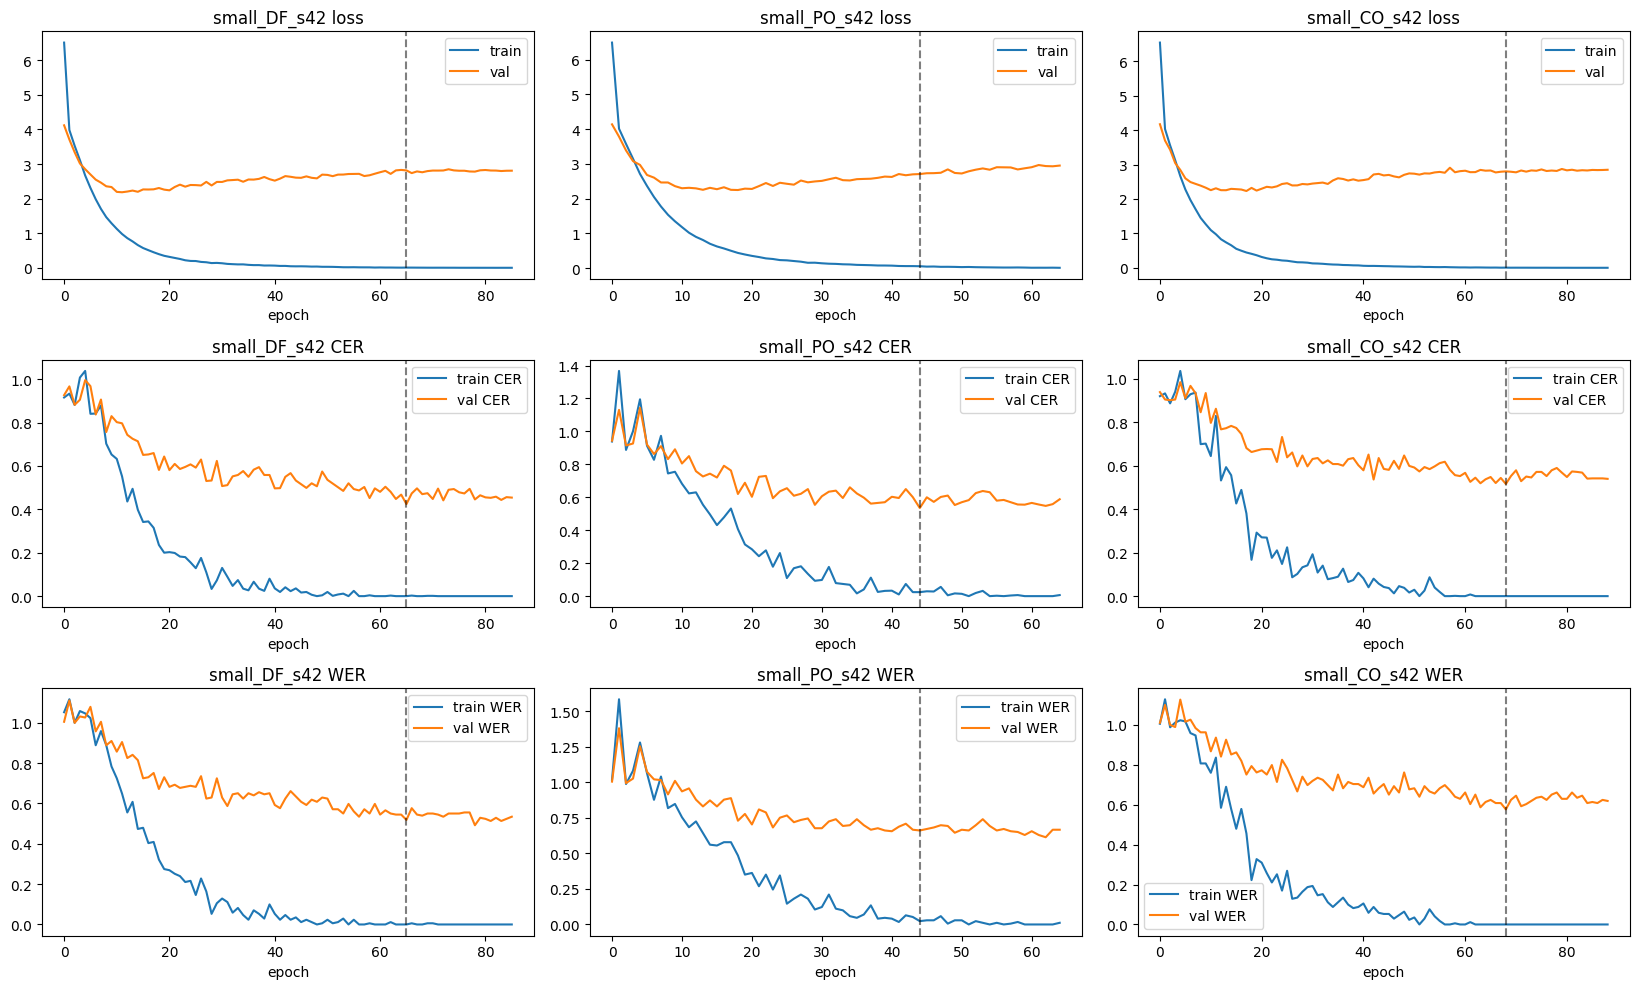

In [29]:
keys = list(histories.keys()) if "histories" in dir() else []
n = len(keys)
if n == 0:
    print("Chưa train, bỏ qua plot.")
else:
    fig, axes = plt.subplots(3, n, figsize=(5.5 * n, 10), squeeze=False)
    for col, k in enumerate(keys):
        h = histories[k]
        ax0, ax1, ax2 = axes[0, col], axes[1, col], axes[2, col]
        best_ep = bests[k]["epoch"]
        ax0.plot(h["train_loss"], label="train")
        ax0.plot(h["val_loss"], label="val")
        ax0.axvline(best_ep - 1, color="k", ls="--", alpha=0.5)
        ax0.set_title(f"{k} loss"); ax0.legend(); ax0.set_xlabel("epoch")
        ax1.plot(h["train_cer"], label="train CER")
        ax1.plot(h["val_cer"], label="val CER")
        ax1.axvline(best_ep - 1, color="k", ls="--", alpha=0.5)
        ax1.set_title(f"{k} CER"); ax1.legend(); ax1.set_xlabel("epoch")
        if "train_wer" in h and "val_wer" in h:
            ax2.plot(h["train_wer"], label="train WER")
            ax2.plot(h["val_wer"], label="val WER")
            ax2.axvline(best_ep - 1, color="k", ls="--", alpha=0.5)
            ax2.set_title(f"{k} WER"); ax2.legend(); ax2.set_xlabel("epoch")
        else:
            ax2.set_visible(False)
    plt.tight_layout(); plt.show()


## 10. Đánh giá trên tập test

**Chỉ chạy sau khi đã khóa phương pháp** (`CFG.final_test = True`). Không dùng test để chọn model / epoch / hyperparameter.


In [34]:
CFG.final_test = True
test_gts = test_df[CFG.label_col].tolist()
rows, test_preds = [], {}

if not CFG.final_test:
    print("CFG.final_test = False → bỏ qua test. Đặt True sau khi khóa phương pháp trên val.")
else:
    for v in CFG.train_views:
        name = VIEW_NAME[v]
        cand = [k for k in ckpts if k.startswith(f"{CFG.preset}_{name}")]
        if not cand:
            print(f"Không có ckpt cho {name}, bỏ qua")
            continue
        # ưu tiên seed 42 nếu có
        key = next((k for k in cand if k.endswith("_s42")), cand[0])
        model = models[key]
        loader = make_loader(test_df, v, train=False)
        _, preds, gts = evaluate(model, loader)
        m = compute_metrics(gts, preds, "strict")
        test_preds[name] = preds
        rows.append({"view": name, "key": key, **{k: round(val, 4) if isinstance(val, float) else val
                                                   for k, val in m.items()}})
        pd.DataFrame({"gt": gts, "pred": preds}).to_csv(
            CFG.out_dir / f"test_pred_{CFG.preset}_{name}.csv", index=False
        )
        print(f"[{name}] test CER {m['CER']:.4f} | SeqAcc {m['SeqAcc']:.4f} | Empty {m['EmptyPred_rate']:.3f}")
        # efficiency (1 batch loader nhỏ)
        eff = measure_efficiency(model, make_loader(test_df.head(16), v, train=False, batch_size=8))
        print(f"  efficiency: {eff}")

    if rows:
        display(pd.DataFrame(rows))


[DF] test CER 0.4480 | SeqAcc 0.4659 | Empty 0.004
  efficiency: {'params_M': 61.596672, 'FPS': 60.19299756035153, 'peak_VRAM_infer_MB': 2521.8076171875}
[PO] test CER 0.6128 | SeqAcc 0.3341 | Empty 0.002
  efficiency: {'params_M': 61.596672, 'FPS': 54.54693667252279, 'peak_VRAM_infer_MB': 2521.8076171875}
[CO] test CER 0.5270 | SeqAcc 0.4374 | Empty 0.007
  efficiency: {'params_M': 61.596672, 'FPS': 64.04979333392366, 'peak_VRAM_infer_MB': 2521.8076171875}


,view,key,CER,WER,SeqAcc,NED,1-NED,CharAcc,Acc<=1edit,Sub_rate,Del_rate,Ins_rate,EmptyPred_rate,LineAcc,n_samples,n_chars
0,DF,small_DF_s42,0.448,0.548,0.466,0.382,0.618,0.552,0.541,0.272,0.103,0.073,0.004,0.495,455,4013
1,PO,small_PO_s42,0.613,0.716,0.334,0.530,0.470,0.387,0.389,0.367,0.165,0.081,0.002,0.336,455,4013
2,CO,small_CO_s42,0.527,0.597,0.437,0.437,0.563,0.473,0.497,0.288,0.158,0.081,0.007,0.445,455,4013


In [35]:
# So sánh nhanh giữa các view (nếu đã train ≥ 2 view)
if not test_preds or len(test_preds) < 2:
    print("Cần ≥ 2 view trên test để oracle / majority (hiện:", list(test_preds.keys()), ")")
else:
    names = list(test_preds.keys())
    correct = np.array([[p == g for p, g in zip(test_preds[n], test_gts)] for n in names])
    print("SeqAcc từng view:", {n: round(float(correct[i].mean()), 4) for i, n in enumerate(names)})
    print("Oracle (≥1 view đúng):", round(float(correct.any(0).mean()), 4))
    if len(names) >= 2:
        best_name = min(names, key=lambda n: next(
            (bests[k]["cer"] for k in bests if n in k), 1.0
        ))
        voted = []
        for k in range(len(test_gts)):
            c = Counter(test_preds[n][k] for n in names).most_common(1)[0]
            voted.append(c[0] if c[1] >= 2 else test_preds[best_name][k])
        print("Majority vote:", compute_metrics(test_gts, voted, "strict"))


SeqAcc từng view: {'DF': 0.4659, 'PO': 0.3341, 'CO': 0.4374}
Oracle (≥1 view đúng): 0.556
Majority vote: {'CER': 0.4325940692748567, 'WER': 0.5217391304347826, 'SeqAcc': 0.49230769230769234, 'NED': 0.3651651137627036, '1-NED': 0.6348348862372963, 'CharAcc': 0.5674059307251433, 'Acc<=1edit': 0.567032967032967, 'Sub_rate': 0.26488911039122853, 'Del_rate': 0.09892848243209569, 'Ins_rate': 0.06877647645153252, 'EmptyPred_rate': 0.004395604395604396, 'LineAcc': 0.516497461928934, 'n_samples': 455, 'n_chars': 4013}


## 11. Phân tích lỗi và gợi ý cho bước fusion

- **Ký tự hay bị nhầm**: giúp quyết định augmentation / charset
- Oracle / majority khi có nhiều view


In [36]:
if not test_preds:
    print("Bỏ qua phân tích lỗi (CFG.final_test = False hoặc chưa có preds).")
else:
    for name, preds in test_preds.items():
        cnt = Counter()
        for g, p in zip(test_gts, preds):
            _, _, _, _, subs = edit_ops(g, p)
            cnt.update(subs)
        print(f"\n=== Confusion [{name}] top-15 ===")
        for (a, b), c in cnt.most_common(15):
            print(f"  {a!r} → {b!r}: {c}")



=== Confusion [DF] top-15 ===
  '1' → '0': 13
  '2' → '1': 10
  '0' → '3': 10
  '1' → '2': 10
  '0' → '2': 10
  '\n' → 'A': 10
  'B' → 'A': 8
  '6' → '4': 8
  '0' → '1': 7
  '6' → '5': 7
  '5' → '4': 7
  '2' → '8': 7
  '1' → '5': 7
  '8' → '1': 7
  '9' → '0': 7

=== Confusion [PO] top-15 ===
  '1' → '2': 15
  '2' → '1': 14
  '4' → '1': 13
  '0' → '8': 12
  '1' → '7': 12
  '0' → '4': 11
  '4' → '2': 10
  '1' → '4': 10
  '\n' → '1': 9
  '3' → '2': 8
  '\n' → '0': 8
  '4' → '5': 8
  '8' → '1': 8
  '2' → '6': 8
  '7' → 'A': 7

=== Confusion [CO] top-15 ===
  '2' → '1': 15
  '0' → '1': 10
  '0' → '7': 10
  '4' → '1': 9
  '0' → '8': 9
  '1' → '4': 9
  '2' → '4': 9
  '1' → '2': 9
  '7' → '1': 8
  '0' → '3': 8
  '4' → '0': 8
  '0' → '2': 8
  '1' → '5': 8
  '2' → '0': 8
  '1' → '7': 8


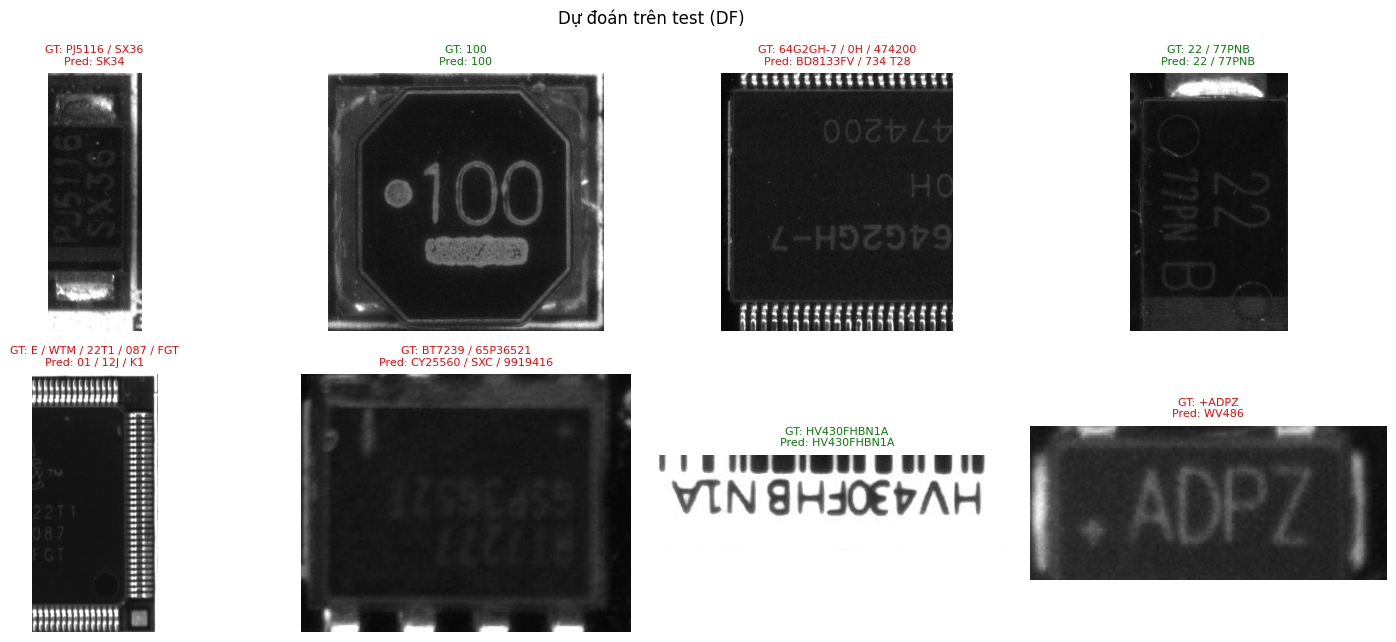

In [37]:
# --- ví dụ dự đoán trên test (đỏ = sai, xanh = đúng) ---
if not test_preds:
    print("Bỏ qua (CFG.final_test = False).")
else:
    def show(s):
        return s.replace("\n", " / ") if s else "(rỗng)"

    name0 = list(test_preds.keys())[0]
    preds0 = test_preds[name0]
    v0 = CFG.train_views[0]
    idx = np.random.RandomState(1).choice(len(test_df), min(8, len(test_df)), replace=False)
    fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
    axes = axes.ravel()
    for a, i in zip(axes, idx):
        a.imshow(load_image(test_df[v0 + "_abs"].iloc[i]))
        ok = preds0[i] == test_gts[i]
        a.set_title(
            f"GT: {show(test_gts[i])}\nPred: {show(preds0[i])}",
            fontsize=8, color="green" if ok else "red",
        )
        a.axis("off")
    plt.suptitle(f"Dự đoán trên test ({name0})")
    plt.tight_layout()
    plt.show()


## 12. Hướng tiếp theo

1. **Chọn preset theo sanity + val CER**: so `small` vs `base`.
2. Confirmation 3 seeds (42/43/44) cho cấu hình tốt nhất.
3. **Crop vùng chữ** / chuẩn hoá hướng trước khi đưa vào TrOCR nếu chữ chỉ chiếm phần nhỏ ảnh.
4. Mở rộng PO/CO + majority vote (§11).
5. Không chạy test đến khi đã khóa phương pháp trên val.


In [38]:
import shutil
from google.colab import files

# Đường dẫn thư mục cần tải về
output_dir = "outputs_trocr_small"
zip_file_name = "outputs_trocr_small.zip"

# Tiến hành nén thư mục
print(f"Đang nén thư mục {output_dir}...")
shutil.make_archive("outputs_trocr_small", 'zip', output_dir)

# Tải file zip về máy
print(f"Đang tải {zip_file_name} về máy...")
files.download(zip_file_name)

Đang nén thư mục outputs_trocr_small...
Đang tải outputs_trocr_small.zip về máy...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>